# pySDIM tutorial: downloading Catalan water data

This notebook shows how to download each kind of data that the ACA's
[SDIM service](https://aplicacions.aca.gencat.cat/sdim21/) offers, using
**pySDIM**:

1. [Setup](#1.-Setup)
2. [Find what you can download](#2.-Find-what-you-can-download)
3. [River water quality](#3.-River-water-quality-(physico-chemical))
4. [Biological indices](#4.-Biological-indices)
5. [River flows and levels](#5.-River-flows-and-river-levels)
6. [Groundwater quality and piezometric levels](#6.-Groundwater)
7. [Reservoir volumes](#7.-Reservoir-volumes)
8. [Protected zones and other categories](#8.-Protected-zones-and-other-categories)
9. [Data before 2007](#9.-Data-before-2007)
10. [Exact queries by code](#10.-Exact-queries-by-code)
11. [Raw files, large requests, checks and provenance](#11.-Raw-files,-large-requests,-checks-and-provenance)

Every download cell sends a few requests to a public service. The examples
use short date ranges and one comarca so they stay light. Please keep your
own queries reasonable too.

> pySDIM is not affiliated with the ACA or the Generalitat de Catalunya. The
> data belongs to the ACA; cite it when you publish results (section 11).

## 1. Setup

Install the package (once):

```bash
python -m pip install pysdim matplotlib
```

`SDIM()` opens the web session for you; no login or cookies are needed.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from sdim import SDIM, Catalog, Query
from sdim.resolver import water_types

aca = SDIM()      # one client for the whole notebook
cat = Catalog()   # the metadata shipped with the package
pd.set_option("display.max_columns", 30)

## 2. Find what you can download

SDIM organises data into **targets**: a period (`after_2007` or
`before_2007`), a control network and a subnetwork. Each target holds one kind
of data (river phys-chem, river flows, groundwater levels, ...).

You rarely need target ids: a `water_type` picks the right one. These are the
named water types:

In [2]:
print("after 2007: ", ", ".join(water_types("after_2007")))
print("before 2007:", ", ".join(water_types("before_2007")))

after 2007:  coastal, coastal_biology, flow, groundwater, lake, lake_biology, levels, protected, reservoir, reservoir_biology, river, river_biology, volumes
before 2007: coastal, coastal_biology, flow, groundwater, levels, protected, reservoir, reservoir_biology, river, river_biology, volumes


All targets, with the number of stations and series each one has:

In [3]:
targets = cat.targets()
targets[["id", "network_name", "subnetwork_name", "category", "station_count"]]

,id,network_name,subnetwork_name,category,station_count
0,after_2007:0001:0001,CONTROL RIUS,Elements biològics,biological,408
1,after_2007:0001:0002,CONTROL RIUS,Substàncies prioritàries i preferents,priority substances; metals,384
2,after_2007:0001:0021,CONTROL RIUS,Elements hidromorfològics,hydromorphological,366
3,after_2007:0001:0022,CONTROL RIUS,Elements fisicoquímics,physical-chemical,446
4,after_2007:0001:0301,CONTROL RIUS,Cabals,quantity,99
5,after_2007:0001:0303,CONTROL RIUS,Nivells,quantity,91
6,after_2007:0002:0003,CONTROL EMBASSAMENTS,Elements biològics,biological,30
7,after_2007:0002:0004,CONTROL EMBASSAMENTS,Substàncies prioritàries i preferents,priority substances; metals,13
8,after_2007:0002:0023,CONTROL EMBASSAMENTS,Elements fisicoquímics,physical-chemical,30
9,after_2007:0002:0302,CONTROL EMBASSAMENTS,Volums,quantity,13


Each target has variable **groups** and **families**, for example
"Índexs biològics > Invertebrats". This is what the river biology target
contains (`sdim describe after_2007:0001:0001` prints the same from a
terminal):

In [4]:
bio_vars = cat.variables_for("0001", "0001", period="after_2007")
bio_vars[["g_name", "f_name", "v_name"]]

,g_name,f_name,v_name
0,Índexs biològics,Fitobentos,índex IPS
1,Índexs biològics,Fitoplàncton,Clorofil·la a
2,Índexs biològics,Invertebrats,índex IBMWP
3,Índexs biològics,Macròfits,índex IMF
4,Índexs biològics,Peixos,índex IBICAT-2010


Search parameter and place names (case- and accent-insensitive):

In [5]:
display(cat.search_variables("nitrat").head())
display(cat.rivers("ter", period="after_2007"))

,period,network,subnetwork,g,g_name,f,f_name,v,v_name
0,after_2007,0003,0025,5,Fisicoquímics,050003,Nutrients,0016,Nitrats
1,after_2007,0004,0008,5,Fisicoquímics,050003,Nutrients,0016,Nitrats
2,after_2007,0004,0008,5,Fisicoquímics,050003,Nutrients,3918,Nitrats (aigua de mar)
3,after_2007,0005,0010,5,Fisicoquímics,050003,Nutrients,0016,Nitrats
4,after_2007,0002,0023,5,Fisicoquímics,050003,Nutrients,0016,Nitrats


,period,code,name
0,after_2007,200,RIU TER
1,after_2007,200190,RIU TERRI


## 3. River water quality (physico-chemical)

Ask by name: water type, place and parameters. Aliases such as `nitrate`,
`phosphate`, `ec` or `temp` map to SDIM's Catalan names.

`get_data()` returns an `SDIMResult`, a dict with a `quality` and a
`quantity` DataFrame. Water-quality data is in `quality`.

In [6]:
res = aca.get_data(
    water_type="river",
    rivers=["Ter"],
    parameters=["nitrate", "phosphate"],
    start="2007-09-01",
    end="2009-12-31",
)
river = res.quality
print(len(river), "rows from", river.station_code.nunique(), "stations")
river[["date", "station_code", "station_name", "variable", "value", "qualifier", "unit"]].head()

319 rows from 11 stations


,date,station_code,station_name,variable,value,qualifier,unit
0,2007-09-03,200015000,El Ter entre el Ges i el Gurri,Nitrats,3.700000,NaN,mg NO3/L
1,2007-09-03,200015000,El Ter entre el Ges i el Gurri,Fosfats,0.240835,NaN,mg PO4/L
2,2007-09-03,200021000,El Ter entre el Gurri i la cua de l'embassamen...,Nitrats,5.100000,NaN,mg NO3/L
3,2007-09-03,200021000,El Ter entre el Gurri i la cua de l'embassamen...,Fosfats,0.454910,NaN,mg PO4/L
4,2007-09-17,200001000,Capçalera del Ter fins a la confluència amb el...,Fosfats,0.200696,NaN,mg PO4/L


`value` is numeric. When SDIM reports a detection limit such as `<0.5`,
`value` is `0.5` and `qualifier` is `"<"`; `value_raw` keeps the original
text. Dates are real datetimes, so plotting just works:

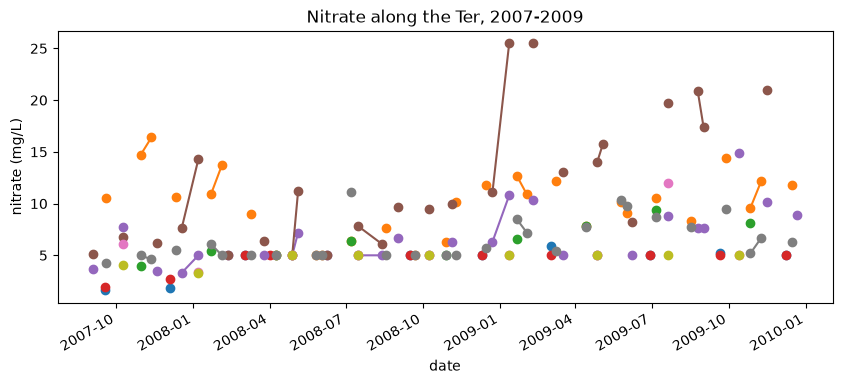

In [7]:
nitrate = river[river.variable.str.contains("Nitrat")]
ax = nitrate.pivot_table(index="date", columns="station_name", values="value").plot(
    marker="o", figsize=(10, 4), legend=False)
ax.set_ylabel("nitrate (mg/L)")
ax.set_title("Nitrate along the Ter, 2007-2009");

## 4. Biological indices

Biological indices (IPS for diatoms, IBMWP for invertebrates, IMF for
macrophytes, IBICAT for fish, ...) are in separate "Elements biològics"
targets. `water_type="river"` alone gives physico-chemical data, so use
`river_biology` (also `lake_biology`, `reservoir_biology`,
`coastal_biology`):

In [8]:
bio = aca.get_data(
    water_type="river_biology",
    comarcas=["Baix Empordà"],
    start="2008-01-01",
    end="2026-01-01",
).quality
bio.groupby("variable").agg(samples=("value", "size"), stations=("station_code", "nunique"),
                            first=("date", "min"), last=("date", "max"))

,samples,stations,first,last
variable,,,,
índex IBICAT-2010,17,7,2016-11-08,2025-11-26
índex IBMWP,55,9,2015-03-12,2025-08-12
índex IMF,20,9,2016-07-17,2024-08-05
índex IPS,57,9,2008-11-06,2025-08-12


Keep a single biological element with `groups` (a group or family name):

In [9]:
ibmwp = aca.get_data(
    water_type="river_biology",
    comarcas=["Baix Empordà"],
    groups=["Invertebrats"],
    start="2008-01-01",
    end="2026-01-01",
).quality
ibmwp.pivot_table(index="station_name", columns=ibmwp.date.dt.year, values="value")

date,2015,2016,2017,2018,2020,2021,2022,2023,2024,2025
station_name,,,,,,,,,,
Capçalera de la riera de Calonge fins al límit del PEIN,130.0,109.0,NaN,NaN,136.0,NaN,100.0,NaN,128.0,NaN
Capçalera del Daró fins a la confluència amb el torrent de la Marqueta (torrent de la Marqueta inclòs),150.5,90.0,141.0,NaN,122.0,106.0,152.0,93.0,143.5,NaN
El Daró entre el torrent de la Marqueta i el Rissec (tram urbà de la Bisbal),47.0,22.0,57.0,30.0,48.0,NaN,43.0,NaN,NaN,NaN
El Ter des de Flaçà fins al mar,73.0,121.0,102.0,74.0,101.0,106.0,115.0,79.0,90.0,85.0
Riera d'Aubi,NaN,39.0,NaN,NaN,30.0,33.0,21.0,NaN,NaN,NaN
Riera de Calonge des del límit del PEIN fins al mar,NaN,34.0,NaN,NaN,101.0,NaN,45.0,NaN,71.0,NaN
"Riu Daró des de la confluència del Rissec fins a Gualta, inclosos el Rissec i la riera de Rupià",53.0,47.0,NaN,NaN,51.0,72.0,39.0,67.0,31.0,NaN
Riu Ridaura des de l'EDAR de Castell-Platja d'Aro fins al mar,50.0,27.0,NaN,NaN,59.0,58.0,20.0,76.0,49.0,NaN


> Reservoir and coastal quality reports currently come back empty from SDIM
> itself (the web interface returns the same empty report), so
> `reservoir_biology` and `coastal_biology` may give no rows.

## 5. River flows and river levels

Flows (*cabals*) and levels (*nivells*) are daily series. They are in the
`quantity` sheet, with `value` holding the daily mean.

In [10]:
flows = aca.get_data(
    water_type="flow",          # or "cabals"
    rivers=["Ter"],
    start="2020-01-01",
    end="2020-03-31",
).quantity
flows[["date", "station_code", "station_name", "variable", "value", "unit"]].head()

,date,station_code,station_name,variable,value,unit
0,2020-01-01,EA139,Aforament - Camprodon (Creixenturri),EA139_Camprodon (Creixenturri)_Cabal riu Ter,0.062003,m³/s
1,2020-01-01,EA138,Aforament - Camprodon (aigua avall CH Matabosc),EA138_Camprodon (aigua avall CH Matabosc)_Caba...,3.118972,m³/s
2,2020-01-01,EA121,Aforament - Colomers (riu i canal de Sentmenat),EA121_Colomers_Cabal riu Ter,3.640972,m³/s
3,2020-01-01,EA010,Aforament - Girona (Ter),EA010_Girona_Cabal riu Ter,3.950817,m³/s
4,2020-01-01,EA141,Aforament - Les Masies de Voltregà,EA141_Les Masies de Voltrega_Cabal riu Ter,2.760063,m³/s


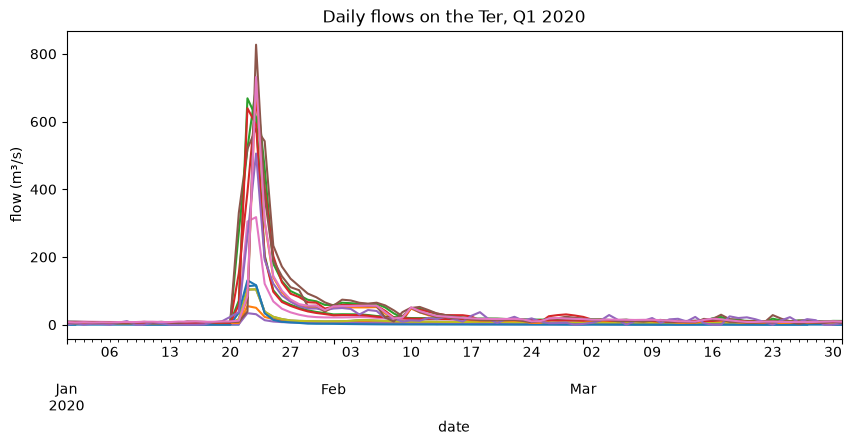

In [11]:
ax = flows.pivot_table(index="date", columns="station_name", values="value").plot(
    figsize=(10, 4), legend=False)
ax.set_ylabel("flow (m³/s)")
ax.set_title("Daily flows on the Ter, Q1 2020");

River levels have no named water type; pick the target by id:

In [12]:
levels = aca.get_data(
    target="after_2007:0001:0303",   # CONTROL RIUS / Nivells
    rivers=["Ter"],
    start="2020-01-01",
    end="2020-01-31",
).quantity
levels.groupby("station_name").value.describe()[["count", "mean", "min", "max"]]

,count,mean,min,max
station_name,,,,
Aforament - Camprodon (Creixenturri),23.0,0.466295,0.028190,1.988156
Aforament - Camprodon (aigua avall CH Matabosc),31.0,0.394559,0.213411,1.215361
Aforament - Colomers (riu i canal de Sentmenat),31.0,0.536826,0.048965,3.161740
Aforament - Girona (Ter),31.0,1.014160,0.655102,2.834931
Aforament - Les Masies de Voltregà,31.0,0.740896,0.229550,3.943301
Aforament - Qualitat - Torroella de Montgrí,31.0,1.020820,0.938481,1.249000
Aforament - Ripoll,31.0,0.670548,0.039800,3.555000
Aforament - Sant Joan de les Abadesses,31.0,1.078135,0.828000,1.857712
Aforament - Sant Joan de les Abadesses (històrica),31.0,1.078135,0.828000,1.857712


## 6. Groundwater

**Water quality** in wells and springs:

In [13]:
gw = aca.get_data(
    water_type="groundwater",
    comarcas=["Baix Empordà"],
    parameters=["nitrate"],
    start="2015-01-01",
    end="2016-12-31",
).quality
gw.groupby("station_name").value.agg(["count", "mean", "max"]).sort_values("max", ascending=False).head(10)

,count,mean,max
station_name,,,
Fluviodeltaic del Baix Ter,53,20.950943,187.0
Paleògens del Baix Ter,20,37.290000,88.4
Al·luvials de la Baixa Costa Brava,23,24.382609,46.4


**Piezometric levels** (`water_type="levels"`). These rows also carry the
well depth and the piezometric level in metres above sea level:

In [14]:
piezo = aca.get_data(
    water_type="levels",
    comarcas=["Baix Empordà"],
    start="2015-01-01",
    end="2016-12-31",
).quality
piezo[["date", "station_code", "variable", "value", "unit",
       "well_depth_m", "piezometric_level_masl"]].head()

,date,station_code,variable,value,unit,well_depth_m,piezometric_level_masl
0,2015-01-21,17057-0051,S24_Angles_Rissec_Nivell Piezometric (F000279N...,6.60,m,16.65,24.99
1,2015-01-21,17068-0058,S8b_Nivell Piezometric_Ter (F000302NPM)_REV0,5.00,m,11.60,10.22
2,2015-01-21,17081-0041,S3c_Nivell Piezometric_Daro (F000306NPM)_REV0,8.28,m,41.10,0.30
3,2015-01-21,17118-0035,Nivell piezomètric (F000483NPM),1.61,m,30.90,6.32
4,2015-01-21,17118-0036,Nivell piezomètric (F000479NPM),2.98,m,22.41,3.76


## 7. Reservoir volumes

Reservoir volumes and levels are daily series in the `quantity` sheet:

In [15]:
vol = aca.get_data(
    water_type="volumes",
    comarcas=["Osona"],     # Sau reservoir
    start="2020-01-01",
    end="2020-03-31",
).quantity
vol.pivot_table(index="date", columns="variable", values="value").head()

variable,E06_Vilanova Sau_Sau_Nivell embassament,E06_Vilanova Sau_Sau_Percentatge volum embassat,E06_Vilanova Sau_Sau_Volum embassament
date,,,
2020-01-01,411.046324,58.148750,96.096624
2020-01-02,411.269642,58.733720,97.063345
2020-01-03,411.388615,59.046033,97.579473
2020-01-04,411.563528,59.506603,98.340613
2020-01-05,411.722924,59.927983,99.036984


## 8. Protected zones and other categories

Protected zones (drinking-water abstraction, river reserves, nitrate
vulnerable zones, ...) are their own network. `groups` narrows a large
target to one family, here nutrients:

In [16]:
prot = aca.get_data(
    water_type="protected",
    comarcas=["Baix Empordà"],
    groups=["Nutrients"],
    start="2015-01-01",
    end="2016-12-31",
)
print(prot.provenance["target_id"], "->", len(prot.quality), "rows")
prot.quality.variable.value_counts()

after_2007:0006:0012 -> 48 rows


variable
Fosfats    12
Nitrats    12
Nitrits    12
Amoni      12
Name: count, dtype: int64

Any `category` from `targets.csv` also works as a `water_type`, for example
`"hydromorphological"`, `"metals"` or `"priority substances"`. Several
networks (rivers, lakes, protected zones) can share a category, and without
more detail the smallest matching target wins, so pin the network:
`networks=["0001"]` is CONTROL RIUS.

In [17]:
hydro = aca.get_data(
    water_type="hydromorphological",
    networks=["0001"],
    comarcas=["Baix Empordà"],
    start="2015-01-01",
    end="2024-12-31",
)
print(hydro.provenance["target_id"])
hydro.quality[["date", "station_name", "variable", "value"]].head()

after_2007:0001:0021


,date,station_name,variable,value
0,2015-03-12,Riu Daró des de la confluència del Rissec fins...,índex IHF,51.0
1,2015-03-12,El Ter des de Flaçà fins al mar,índex IHF,87.0
2,2015-05-12,Capçalera del Daró fins a la confluència amb e...,índex IHF,55.0
3,2015-05-12,Capçalera del Daró fins a la confluència amb e...,índex IHF,76.0
4,2015-05-12,El Daró entre el torrent de la Marqueta i el R...,índex IHF,45.0


## 9. Data before 2007

SDIM keeps data from before 2007 in a separate archive. Add
`period="before_2007"`; the same water types work where that archive has
the data. Before 2007, river and reservoir quality share one target, and
there is no lake network.

In [18]:
old = aca.get_data(
    period="before_2007",
    water_type="groundwater",
    comarcas=["Baix Empordà"],
    parameters=["nitrate"],
    start="2000-01-01",
    end="2006-12-31",
).quality
print(old.date.min().date(), "to", old.date.max().date(), "-", old.station_code.nunique(), "stations")

2000-01-19 to 2006-12-20 - 131 stations


For a long series, query each period and join the results:

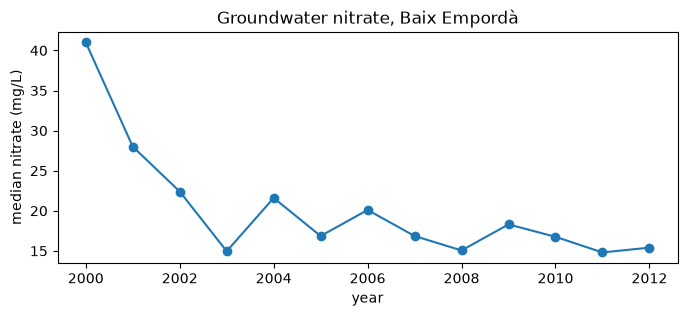

In [19]:
recent = aca.get_data(
    water_type="groundwater",
    comarcas=["Baix Empordà"],
    parameters=["nitrate"],
    start="2007-01-01",
    end="2012-12-31",
).quality
both = pd.concat([old, recent], ignore_index=True)
yearly = both.groupby(both.date.dt.year).value.median()
ax = yearly.plot(marker="o", figsize=(8, 3))
ax.set_xlabel("year"); ax.set_ylabel("median nitrate (mg/L)")
ax.set_title("Groundwater nitrate, Baix Empordà");

## 10. Exact queries by code

When you know SDIM's internal codes, build a `Query` yourself. This is
conductivity at two Ter stations (station → series ids come from
`cat.target_station_variables(...)`):

In [20]:
q = Query(
    period="after_2007",
    networks=["0001"],              # CONTROL RIUS
    subnetworks=["0022"],           # Elements fisicoquímics
    variable_kinds=[("g", "5"), ("f", "050004"), ("v", "0002")],  # Conductivitat
    ambit="riu",
    spatial={"riuAmbit": ["200"]},  # RIU TER
    stations={"F007528": ["3057279"], "F007529": ["3049297"]},
    start="2007-09-01",
    end="2010-01-01",
)
cond = aca.get_data(q).quality
cond[["date", "station_name", "variable", "value", "unit"]].head()

,date,station_name,variable,value,unit
0,2007-09-17,Capçalera del Ter fins a la confluència amb el...,Conductivitat (camp),194.0,µS/cm
1,2007-10-09,El Ter entre el Ritort i el Freser,Conductivitat (camp),293.0,µS/cm
2,2007-12-04,Capçalera del Ter fins a la confluència amb el...,Conductivitat (camp),209.0,µS/cm
3,2008-01-07,El Ter entre el Ritort i el Freser,Conductivitat (camp),341.0,µS/cm
4,2008-03-03,Capçalera del Ter fins a la confluència amb el...,Conductivitat (camp),266.0,µS/cm


## 11. Raw files, large requests, checks and provenance

**Raw file.** `download()` returns SDIM's own Excel export:

In [21]:
raw = aca.download(water_type="river_biology", comarcas=["Baix Empordà"],
                   start="2020-01-01", end="2020-12-31", output="tutorial_raw.xlsx")
print(len(raw), "bytes written to tutorial_raw.xlsx")

6480 bytes written to tutorial_raw.xlsx


**Large requests.** SDIM refuses reports above its record limit.
`get_data()` then splits the request by stations and by date range and joins
the parts (`split=False` turns this off, and `max_requests` caps the number
of reports). Temporary server errors are retried with backoff, and a failed
report is regenerated in a fresh session.

**Checks.** If SDIM changes its export so that a key column comes back empty,
`get_data()` raises `SDIMParseError` instead of returning broken data. Empty
reports or stations missing from the catalog give an `SDIMWarning`.

**Provenance.** Each result records where and when the data came from:

In [22]:
res.provenance

{'source': "Agència Catalana de l'Aigua (ACA), SDIM",
 'source_url': 'https://aplicacions.aca.gencat.cat/sdim21/',
 'accessed_at': '2026-10-26T10:23:27+00:00',
 'target_id': 'after_2007:0001:0022',
 'period': 'after_2007',
 'networks': ['0001'],
 'subnetworks': ['0022'],
 'start': '2007-09-01',
 'end': '2009-12-31',
 'stations': 11,
 'requests': 1,
 'client': 'pysdim 1.0.1',
 'citation': 'Abert-Fernandez, D., Madaula, E., Gonzalvo-Henry, G., Menció, A., Monclús, H. pySDIM — Python client for ACA SDIM water data. https://doi.org/10.5281/zenodo.22661965'}

Save the data with its provenance next to it: one CSV per sheet and a JSON
file you can cite from.

In [23]:
paths = res.save("tutorial_output/ter_nutrients")
[str(p) for p in paths]

['tutorial_output\\ter_nutrients_quality.csv',
 'tutorial_output\\ter_nutrients_provenance.json']

**Citing.** When you publish results, cite the ACA as the data source with
the access date from `provenance["accessed_at"]`, and cite pySDIM:

> David Abert-Fernandez, Eduard Madaula, Gisela Gonzalvo-Henry, Anna Menció,
> Hèctor Monclús. *pySDIM — Python client for ACA SDIM water data*.
> DOI: 10.5281/zenodo.22661965

Close the session when you are done:

In [24]:
aca.close()